# EDA de los resultados electorales de las Elecciones Generales del Perú 2026

Realizar un análisis exploratorio de los archivos JSON descargados del portal histórico de la ONPE para conocer su estructura, evaluar su calidad y determinar si la información disponible permite construir una base de datos relacional para el sistema Text-to-SQL.

## 1. Configuración y reproducibilidad

En esta sección se definen las rutas, parámetros y semilla de reproducibilidad. La semilla se utiliza para que las muestras aleatorias de registros sean repetibles.

**Variables principales:**

- `PROJECT_ROOT`: carpeta raíz del repositorio.
- `DATA_DIR`: carpeta que contiene los archivos JSON originales de ONPE.
- `OUTPUT_DIR`: carpeta donde se guardarán tablas y resultados del EDA.
- `RANDOM_SEED`: semilla utilizada para seleccionar muestras reproducibles.

In [1]:
from pathlib import Path
import json
import hashlib
import logging
import random
import re
import unicodedata
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "ONPE_2026" / "Peru"

OUTPUT_DIR = PROJECT_ROOT / "results" / "eda"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Semilla para que las muestras aleatorias sean reproducibles.
RANDOM_SEED = 31
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Configuración de visualización.
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (10, 5)

print("Raíz del proyecto:", PROJECT_ROOT)
print("Directorio de datos:", DATA_DIR)
print("Directorio de resultados:", OUTPUT_DIR)
print("Semilla:", RANDOM_SEED)

Raíz del proyecto: c:\Users\Kencho\Desktop\MaestriaIA\Trabajo Investigacion II\Repositorio\ProyectoTesis
Directorio de datos: c:\Users\Kencho\Desktop\MaestriaIA\Trabajo Investigacion II\Repositorio\ProyectoTesis\data\raw\ONPE_2026\Peru
Directorio de resultados: c:\Users\Kencho\Desktop\MaestriaIA\Trabajo Investigacion II\Repositorio\ProyectoTesis\results\eda
Semilla: 31


### 1.1 Comprobación de la ruta de datos

Antes de continuar, verifica que `DATA_DIR` apunte a la carpeta que contiene los archivos descargados.

El notebook buscará recursivamente archivos llamados `participantes.json` y `totales.json`. También registrará otros JSON para que puedas revisar si existen archivos adicionales relevantes.

In [2]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"No se encontró el directorio: {DATA_DIR}\n"
        "Modifica DATA_DIR en la sección 1 para indicar la ubicación de tus JSON."
    )

json_files = sorted(DATA_DIR.rglob("*.json"))

print(f"Archivos JSON encontrados: {len(json_files):,}")
print("Primeros archivos:")
for path in json_files[:10]:
    print(" -", path.relative_to(DATA_DIR))

Archivos JSON encontrados: 4,450
Primeros archivos:
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\totales.json
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\participantes.json
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\totales.json
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\participantes.json
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\totales.json
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\participantes.json
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\totales.json
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\participantes.json
 - 010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\totales.json


## 2. Inventario de archivos y versión del conjunto de datos

Inventario de los archivos para ver la composición del conjunto de datos. Se registrarán nombre, ruta relativa, tamaño y fecha de modificación del archivo.

In [3]:
inventory_rows = []

for path in json_files:
    stat = path.stat()
    inventory_rows.append({
        "archivo": path.name,
        "ruta_relativa": str(path.relative_to(DATA_DIR)),
        "tamano_bytes": stat.st_size,
        "fecha_modificacion_local": datetime.fromtimestamp(stat.st_mtime).isoformat(timespec="seconds")
    })

df_inventory = pd.DataFrame(inventory_rows)

display(df_inventory.head(10))

if not df_inventory.empty:
    print("\nResumen de tamaños (bytes):")
    display(df_inventory["tamano_bytes"].describe().to_frame())

    print("\nCantidad de archivos por nombre:")
    display(df_inventory["archivo"].value_counts().to_frame("cantidad"))

,archivo,ruta_relativa,tamano_bytes,fecha_modificacion_local
0,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json,9006,2026-10-16T15:32:24
1,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\totales.json,477,2026-10-16T15:32:23
2,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\participantes.json,8903,2026-10-16T15:32:21
3,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\totales.json,471,2026-10-16T15:32:20
4,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\participantes.json,8929,2026-10-16T15:32:22
5,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\totales.json,471,2026-10-16T15:32:22
6,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\participantes.json,8905,2026-10-16T15:32:25
7,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\totales.json,471,2026-10-16T15:32:24
8,participantes.json,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\participantes.json,8909,2026-10-16T15:32:26
9,totales.json,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\totales.json,471,2026-10-16T15:32:26



Resumen de tamaños (bytes):


,tamano_bytes
count,4450.000000
mean,4506.131236
std,4243.164189
min,76.000000
25%,475.000000
50%,482.000000
75%,8964.000000
max,9111.000000



Cantidad de archivos por nombre:


,cantidad
archivo,
participantes.json,2113
totales.json,2113
distritos.json,196
provincias.json,25
departamentos.json,1
participantes_nacional.json,1
totales_nacional.json,1


In [4]:
# Huella SHA-256 del conjunto de archivos: permite identificar la versión analizada.
# Se calcula combinando rutas relativas y contenido de cada archivo.
sha256 = hashlib.sha256()

for path in json_files:
    sha256.update(str(path.relative_to(DATA_DIR)).encode("utf-8"))
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

DATASET_SHA256 = sha256.hexdigest() if json_files else None
print("SHA-256 del conjunto de archivos:", DATASET_SHA256)

SHA-256 del conjunto de archivos: 57f1c04bbae4c4e066bdbe9879521a56bab2442f5d5569ac8aeec87ed14d4058


## 3. Carga de archivos JSON

Comprobando la estructura exacta de los JSON antes de asumir nombres de columnas. La función siguiente admite:

- Un objeto JSON (`dict`), que se interpreta como un registro.
- Una lista JSON (`list`), cuyos elementos se interpretan como registros.
- Un objeto que contiene una lista de registros en una de sus propiedades.

Si un archivo tiene una estructura distinta, se mostrará el error para que pueda inspeccionarse sin descartar silenciosamente el archivo.

In [5]:
def payload_to_records(payload):
    """Convierte un JSON en una lista de diccionarios, sin asumir un esquema específico."""
    if isinstance(payload, list):
        return [item for item in payload if isinstance(item, dict)]

    if isinstance(payload, dict):
        # Si existe una propiedad cuyo valor es una lista de objetos, se toma como colección.
        list_candidates = [
            value for value in payload.values()
            if isinstance(value, list) and all(isinstance(x, dict) for x in value)
        ]
        if len(list_candidates) == 1:
            return list_candidates[0]
        return [payload]

    return []


def load_json_group(paths, expected_name):
    """Carga todos los archivos que coinciden con expected_name y conserva su procedencia."""
    frames = []
    errors = []

    for path in paths:
        if path.name.lower() != expected_name.lower():
            continue

        try:
            with path.open("r", encoding="utf-8") as file:
                payload = json.load(file)

            records = payload_to_records(payload)
            if records:
                frame = pd.json_normalize(records, sep=".")
                frame["source_file"] = str(path.relative_to(DATA_DIR))
                frames.append(frame)
            else:
                errors.append({
                    "archivo": str(path.relative_to(DATA_DIR)),
                    "error": "El JSON no contiene objetos que puedan convertirse en registros."
                })
        except Exception as exc:
            errors.append({
                "archivo": str(path.relative_to(DATA_DIR)),
                "error": repr(exc)
            })

    combined = pd.concat(frames, ignore_index=True, sort=False) if frames else pd.DataFrame()
    return combined, pd.DataFrame(errors)


df_participantes, errors_participantes = load_json_group(json_files, "participantes.json")
df_totales, errors_totales = load_json_group(json_files, "totales.json")

print("Registros cargados desde participantes.json:", len(df_participantes))
print("Registros cargados desde totales.json:", len(df_totales))
print("Errores participantes:", len(errors_participantes))
print("Errores totales:", len(errors_totales))

display(errors_participantes.head())
display(errors_totales.head())

Registros cargados desde participantes.json: 76068
Registros cargados desde totales.json: 2113
Errores participantes: 0
Errores totales: 0


""


""


### 3.1 Inspección inicial de la estructura

Se mostrarán las dimensiones, columnas y algunos registros de cada conjunto. Una fila representa un registro producido por la lectura del JSON.

In [6]:
def inspect_dataframe(df, name):
    print(f"\n===== {name} =====")
    print("Filas:", df.shape[0])
    print("Columnas:", df.shape[1])
    print("\nColumnas detectadas:")
    for column in df.columns:
        print(" -", column)
    print("\nMuestra de registros:")
    display(df.head(5))

inspect_dataframe(df_participantes, "PARTICIPANTES")
inspect_dataframe(df_totales, "TOTALES")


===== PARTICIPANTES =====
Filas: 76068
Columnas: 8

Columnas detectadas:
 - nombreAgrupacionPolitica
 - codigoAgrupacionPolitica
 - nombreCandidato
 - dniCandidato
 - totalVotosValidos
 - porcentajeVotosValidos
 - porcentajeVotosEmitidos
 - source_file

Muestra de registros:


,nombreAgrupacionPolitica,codigoAgrupacionPolitica,nombreCandidato,dniCandidato,totalVotosValidos,porcentajeVotosValidos,porcentajeVotosEmitidos,source_file
0,PARTIDO DE LOS TRABAJADORES Y EMPRENDEDORES PTE - PERÚ,15,NAPOLEON BECERRA GARCIA,08058852,0,0.000,0.000,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json
1,PERÚ MODERNO,4,CARLOS ERNESTO JAICO CARRANZA,06529088,7,0.052,0.042,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json
2,SALVEMOS AL PERÚ,36,ANTONIO ORTIZ VILLANO,08587486,8,0.059,0.049,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json
3,FE EN EL PERÚ,5,ALVARO GONZALO PAZ DE LA BARRA FREIGEIRO,41904418,11,0.082,0.067,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json
4,PARTIDO POLÍTICO PRIN,30,WALTER GILMER CHIRINOS PURIZAGA,18870364,12,0.089,0.073,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json



===== TOTALES =====
Filas: 2113
Columnas: 20

Columnas detectadas:
 - success
 - message
 - data.actasContabilizadas
 - data.contabilizadas
 - data.totalActas
 - data.participacionCiudadana
 - data.actasEnviadasJee
 - data.enviadasJee
 - data.actasPendientesJee
 - data.pendientesJee
 - data.fechaActualizacion
 - data.idUbigeoDepartamento
 - data.idUbigeoProvincia
 - data.idUbigeoDistrito
 - data.idUbigeoDistritoElectoral
 - data.totalVotosEmitidos
 - data.totalVotosValidos
 - data.porcentajeVotosEmitidos
 - data.porcentajeVotosValidos
 - source_file

Muestra de registros:


,success,message,data.actasContabilizadas,data.contabilizadas,data.totalActas,data.participacionCiudadana,data.actasEnviadasJee,data.enviadasJee,data.actasPendientesJee,data.pendientesJee,data.fechaActualizacion,data.idUbigeoDepartamento,data.idUbigeoProvincia,data.idUbigeoDistrito,data.idUbigeoDistritoElectoral,data.totalVotosEmitidos,data.totalVotosValidos,data.porcentajeVotosEmitidos,data.porcentajeVotosValidos,source_file
0,True,,100.0,76,76,74.824,0.0,0,0.0,0,1781884800569,140000,140100,140101,15,16471,13472,100,100,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\totales.json
1,True,,100.0,2,2,57.475,0.0,0,0.0,0,1781884800569,140000,140100,140101,15,173,121,100,100,010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\totales.json
2,True,,100.0,5,5,64.238,0.0,0,0.0,0,1781884800569,140000,140100,140101,15,776,611,100,100,010000_AMAZONAS\010100_CHACHAPOYAS\010103_BALSAS\totales.json
3,True,,100.0,3,3,70.728,0.0,0,0.0,0,1781884800569,140000,140100,140101,15,476,365,100,100,010000_AMAZONAS\010100_CHACHAPOYAS\010104_CHETO\totales.json
4,True,,100.0,4,4,51.285,0.0,0,0.0,0,1781884800569,140000,140100,140101,15,519,380,100,100,010000_AMAZONAS\010100_CHACHAPOYAS\010105_CHILIQUIN\totales.json


### 3.2 Carga de catálogos geográficos

Se incorporan los catálogos oficiales de departamentos, provincias y distritos. Estos archivos permiten describir los códigos UBIGEO y, posteriormente, relacionar los resultados electorales con sus nombres geográficos.

Esta incorporación es adicional: no reemplaza ni modifica la carga de `participantes.json` y `totales.json`.

In [7]:
# Carga de los tres catálogos geográficos usando la función definida en la sección 3.
df_departamentos, errors_departamentos = load_json_group(
    json_files, "departamentos.json"
)
df_provincias, errors_provincias = load_json_group(
    json_files, "provincias.json"
)
df_distritos, errors_distritos = load_json_group(
    json_files, "distritos.json"
)

print("Registros cargados desde departamentos.json:", len(df_departamentos))
print("Registros cargados desde provincias.json:", len(df_provincias))
print("Registros cargados desde distritos.json:", len(df_distritos))

print("\nErrores de carga:")
print("departamentos.json:", len(errors_departamentos))
print("provincias.json:", len(errors_provincias))
print("distritos.json:", len(errors_distritos))

display(errors_departamentos.head())
display(errors_provincias.head())
display(errors_distritos.head())

Registros cargados desde departamentos.json: 25
Registros cargados desde provincias.json: 196
Registros cargados desde distritos.json: 1892

Errores de carga:
departamentos.json: 0
provincias.json: 0
distritos.json: 0


""


""


""


### 3.3 Inspección inicial de los catálogos geográficos

Se revisan las dimensiones, los nombres de las columnas y una muestra de registros de cada catálogo. La inspección permite confirmar la estructura real de los JSON antes de utilizarlos en cruces por UBIGEO.

In [8]:
inspect_dataframe(df_departamentos, "CATÁLOGO DE DEPARTAMENTOS")
inspect_dataframe(df_provincias, "CATÁLOGO DE PROVINCIAS")
inspect_dataframe(df_distritos, "CATÁLOGO DE DISTRITOS")


===== CATÁLOGO DE DEPARTAMENTOS =====
Filas: 25
Columnas: 3

Columnas detectadas:
 - ubigeo
 - nombre
 - source_file

Muestra de registros:


,ubigeo,nombre,source_file
0,010000,AMAZONAS,departamentos.json
1,020000,ÁNCASH,departamentos.json
2,030000,APURÍMAC,departamentos.json
3,040000,AREQUIPA,departamentos.json
4,050000,AYACUCHO,departamentos.json



===== CATÁLOGO DE PROVINCIAS =====
Filas: 196
Columnas: 3

Columnas detectadas:
 - ubigeo
 - nombre
 - source_file

Muestra de registros:


,ubigeo,nombre,source_file
0,010200,BAGUA,010000_AMAZONAS\provincias.json
1,010300,BONGARÁ,010000_AMAZONAS\provincias.json
2,010100,CHACHAPOYAS,010000_AMAZONAS\provincias.json
3,010600,CONDORCANQUI,010000_AMAZONAS\provincias.json
4,010400,LUYA,010000_AMAZONAS\provincias.json



===== CATÁLOGO DE DISTRITOS =====
Filas: 1892
Columnas: 3

Columnas detectadas:
 - ubigeo
 - nombre
 - source_file

Muestra de registros:


,ubigeo,nombre,source_file
0,010102,ASUNCIÓN,010000_AMAZONAS\010100_CHACHAPOYAS\distritos.json
1,010103,BALSAS,010000_AMAZONAS\010100_CHACHAPOYAS\distritos.json
2,010101,CHACHAPOYAS,010000_AMAZONAS\010100_CHACHAPOYAS\distritos.json
3,010104,CHETO,010000_AMAZONAS\010100_CHACHAPOYAS\distritos.json
4,010105,CHILIQUIN,010000_AMAZONAS\010100_CHACHAPOYAS\distritos.json


### 3.4 Inspección de un archivo JSON individual

Esta celda permite visualizar la estructura original de un archivo concreto. Es útil cuando se necesita confirmar el significado de una columna o entender cómo están anidados los datos.

In [10]:
if json_files:
    SAMPLE_JSON = json_files[2]
    print("Archivo inspeccionado:", SAMPLE_JSON.relative_to(DATA_DIR))
    with SAMPLE_JSON.open("r", encoding="utf-8") as file:
        sample_payload = json.load(file)
    print(json.dumps(sample_payload, ensure_ascii=False, indent=2)[:10000])
else:
    print("No hay archivos JSON para inspeccionar.")

Archivo inspeccionado: 010000_AMAZONAS\010100_CHACHAPOYAS\010102_ASUNCIÓN\participantes.json
{
  "success": true,
  "message": "",
  "data": [
    {
      "nombreAgrupacionPolitica": "PARTIDO DEMÓCRATA VERDE",
      "codigoAgrupacionPolitica": 18,
      "nombreCandidato": "ALEX GONZALES CASTILLO",
      "dniCandidato": "09307547",
      "totalVotosValidos": 0,
      "porcentajeVotosValidos": 0.0,
      "porcentajeVotosEmitidos": 0.0
    },
    {
      "nombreAgrupacionPolitica": "PROGRESEMOS",
      "codigoAgrupacionPolitica": 34,
      "nombreCandidato": "PAUL DAVIS JAIMES BLANCO",
      "dniCandidato": "40139245",
      "totalVotosValidos": 0,
      "porcentajeVotosValidos": 0.0,
      "porcentajeVotosEmitidos": 0.0
    },
    {
      "nombreAgrupacionPolitica": "PODEMOS PERÚ",
      "codigoAgrupacionPolitica": 32,
      "nombreCandidato": "JOSE LEON LUNA GALVEZ",
      "dniCandidato": "07246887",
      "totalVotosValidos": 0,
      "porcentajeVotosValidos": 0.0,
      "porcentajeVot

## 4. Calidad de los datos

Se revisarán valores nulos, tipos de datos, registros duplicados y valores numéricos. Estos controles permiten detectar problemas que podrían trasladarse a la base relacional y provocar consultas SQL incorrectas.

### 4.1 Valores nulos

El porcentaje de nulos se calcula por columna:

`porcentaje_nulos = cantidad_de_nulos / total_de_filas * 100`

In [11]:
def null_summary(df, name):
    if df.empty:
        print(f"{name}: no hay datos cargados.")
        return pd.DataFrame()

    summary = pd.DataFrame({
        "nulos": df.isna().sum(),
        "porcentaje_nulos": (df.isna().mean() * 100).round(2),
        "tipo_dato": df.dtypes.astype(str)
    }).sort_values("porcentaje_nulos", ascending=False)

    print(f"Resumen de valores nulos: {name}")
    display(summary)
    return summary

nulls_participantes = null_summary(df_participantes, "participantes")
nulls_totales = null_summary(df_totales, "totales")

Resumen de valores nulos: participantes


,nulos,porcentaje_nulos,tipo_dato
nombreAgrupacionPolitica,0,0.0,str
codigoAgrupacionPolitica,0,0.0,int64
nombreCandidato,0,0.0,str
dniCandidato,0,0.0,str
totalVotosValidos,0,0.0,int64
porcentajeVotosValidos,0,0.0,float64
porcentajeVotosEmitidos,0,0.0,float64
source_file,0,0.0,str


Resumen de valores nulos: totales


,nulos,porcentaje_nulos,tipo_dato
success,0,0.0,bool
message,0,0.0,str
data.actasContabilizadas,0,0.0,float64
data.contabilizadas,0,0.0,int64
data.totalActas,0,0.0,int64
data.participacionCiudadana,0,0.0,float64
data.actasEnviadasJee,0,0.0,float64
data.enviadasJee,0,0.0,int64
data.actasPendientesJee,0,0.0,float64
data.pendientesJee,0,0.0,int64


### 4.2 Tipos de datos y cardinalidad

La cardinalidad indica cuántos valores distintos tiene una columna. Es útil para reconocer identificadores, categorías y campos con valores repetidos.

Por ejemplo, un código geográfico debería tener una cantidad de valores distintos coherente con el nivel territorial que representa.

In [12]:
def column_profile(df, name):
    if df.empty:
        return pd.DataFrame()

    rows = []
    for column in df.columns:
        rows.append({
            "columna": column,
            "tipo": str(df[column].dtype),
            "valores_no_nulos": int(df[column].notna().sum()),
            "valores_distintos": int(df[column].nunique(dropna=True)),
            "ejemplos": " | ".join(df[column].dropna().astype(str).head(3).tolist())
        })

    result = pd.DataFrame(rows)
    print(f"Perfil de columnas: {name}")
    display(result)
    return result

profile_participantes = column_profile(df_participantes, "participantes")
profile_totales = column_profile(df_totales, "totales")

Perfil de columnas: participantes


,columna,tipo,valores_no_nulos,valores_distintos,ejemplos
0,nombreAgrupacionPolitica,str,76068,36,PARTIDO DE LOS TRABAJADORES Y EMPRENDEDORES PTE - PERÚ | PERÚ MODERNO | SALVEMOS AL PERÚ
1,codigoAgrupacionPolitica,int64,76068,36,15 | 4 | 36
2,nombreCandidato,str,76068,36,NAPOLEON BECERRA GARCIA | CARLOS ERNESTO JAICO CARRANZA | ANTONIO ORTIZ VILLANO
3,dniCandidato,str,76068,36,08058852 | 06529088 | 08587486
4,totalVotosValidos,int64,76068,4247,0 | 7 | 8
5,porcentajeVotosValidos,float64,76068,12406,0.0 | 0.052 | 0.059
6,porcentajeVotosEmitidos,float64,76068,11135,0.0 | 0.042 | 0.049
7,source_file,str,76068,2113,010000_AMAZONAS\010100_CHACHAPOYAS\010101_CHACHAPOYAS\participantes.json | 010000_AMAZONAS\010100_CHACHAPOYAS\010101...


Perfil de columnas: totales


,columna,tipo,valores_no_nulos,valores_distintos,ejemplos
0,success,bool,2113,1,True | True | True
1,message,str,2113,1,| |
2,data.actasContabilizadas,float64,2113,1,100.0 | 100.0 | 100.0
3,data.contabilizadas,int64,2113,344,76 | 2 | 5
4,data.totalActas,int64,2113,344,76 | 2 | 5
5,data.participacionCiudadana,float64,2113,2053,74.824 | 57.475 | 64.238
6,data.actasEnviadasJee,float64,2113,1,0.0 | 0.0 | 0.0
7,data.enviadasJee,int64,2113,1,0 | 0 | 0
8,data.actasPendientesJee,float64,2113,1,0.0 | 0.0 | 0.0
9,data.pendientesJee,int64,2113,1,0 | 0 | 0


### 4.3 Registros duplicados

Se calcularán duplicados exactos de fila. Este control no identifica necesariamente duplicados lógicos: dos filas pueden tener valores iguales en campos importantes y diferir en metadatos, o una fila puede ser válida aunque comparta algunos campos con otra.

In [13]:
def duplicate_summary(df, name):
    if df.empty:
        return {"conjunto": name, "filas": 0, "duplicados_exactos": 0}

    duplicated_count = int(df.duplicated().sum())
    result = {
        "conjunto": name,
        "filas": len(df),
        "duplicados_exactos": duplicated_count,
        "porcentaje_duplicados": round(duplicated_count / len(df) * 100, 2)
    }
    print(result)
    return result

duplicate_results = pd.DataFrame([
    duplicate_summary(df_participantes, "participantes"),
    duplicate_summary(df_totales, "totales")
])
display(duplicate_results)

{'conjunto': 'participantes', 'filas': 76068, 'duplicados_exactos': 0, 'porcentaje_duplicados': 0.0}
{'conjunto': 'totales', 'filas': 2113, 'duplicados_exactos': 0, 'porcentaje_duplicados': 0.0}


,conjunto,filas,duplicados_exactos,porcentaje_duplicados
0,participantes,76068,0,0.0
1,totales,2113,0,0.0


### 4.4 Perfil de calidad de los catálogos

Se aplican a los tres catálogos los controles de valores nulos, tipos de datos, cardinalidad y duplicados que ya están definidos en las secciones anteriores. No se presupone aquí el nombre de la columna UBIGEO: primero se inspeccionan las columnas detectadas.

In [14]:
# Resumen de valores nulos.
nulls_departamentos = null_summary(df_departamentos, "departamentos")
nulls_provincias = null_summary(df_provincias, "provincias")
nulls_distritos = null_summary(df_distritos, "distritos")

# Perfil de columnas: tipo de dato y cardinalidad.
profile_departamentos = column_profile(df_departamentos, "departamentos")
profile_provincias = column_profile(df_provincias, "provincias")
profile_distritos = column_profile(df_distritos, "distritos")

display(profile_departamentos)
display(profile_provincias)
display(profile_distritos)

# Duplicados exactos de fila.
duplicate_departamentos = duplicate_summary(df_departamentos, "departamentos")
duplicate_provincias = duplicate_summary(df_provincias, "provincias")
duplicate_distritos = duplicate_summary(df_distritos, "distritos")

display(pd.DataFrame([
    duplicate_departamentos,
    duplicate_provincias,
    duplicate_distritos
]))

Resumen de valores nulos: departamentos


,nulos,porcentaje_nulos,tipo_dato
ubigeo,0,0.0,str
nombre,0,0.0,str
source_file,0,0.0,str


Resumen de valores nulos: provincias


,nulos,porcentaje_nulos,tipo_dato
ubigeo,0,0.0,str
nombre,0,0.0,str
source_file,0,0.0,str


Resumen de valores nulos: distritos


,nulos,porcentaje_nulos,tipo_dato
ubigeo,0,0.0,str
nombre,0,0.0,str
source_file,0,0.0,str


... (7 outputs left out)

,columna,tipo,valores_no_nulos,valores_distintos,ejemplos
0,ubigeo,str,196,196,010200 | 010300 | 010100
1,nombre,str,196,196,BAGUA | BONGARÁ | CHACHAPOYAS
2,source_file,str,196,25,010000_AMAZONAS\provincias.json | 010000_AMAZONAS\provincias.json | 010000_AMAZONAS\provincias.json


,columna,tipo,valores_no_nulos,valores_distintos,ejemplos
0,ubigeo,str,1892,1892,010102 | 010103 | 010101
1,nombre,str,1892,1736,ASUNCIÓN | BALSAS | CHACHAPOYAS
2,source_file,str,1892,196,010000_AMAZONAS\010100_CHACHAPOYAS\distritos.json | 010000_AMAZONAS\010100_CHACHAPOYAS\distritos.json | 010000_AMAZO...


{'conjunto': 'departamentos', 'filas': 25, 'duplicados_exactos': 0, 'porcentaje_duplicados': 0.0}
{'conjunto': 'provincias', 'filas': 196, 'duplicados_exactos': 0, 'porcentaje_duplicados': 0.0}
{'conjunto': 'distritos', 'filas': 1892, 'duplicados_exactos': 0, 'porcentaje_duplicados': 0.0}


,conjunto,filas,duplicados_exactos,porcentaje_duplicados
0,departamentos,25,0,0.0
1,provincias,196,0,0.0
2,distritos,1892,0,0.0


### 4.5 Rangos y valores numéricos

Resume las columnas numéricas para identificar mínimos, máximos, promedios y posibles valores atípicos. 
La regla del rango intercuartílico (IQR) se utiliza únicamente como señal exploratoria:

- `IQR = Q3 - Q1`
- Límite inferior = `Q1 - 1.5 * IQR`
- Límite superior = `Q3 + 1.5 * IQR`

In [15]:
def numeric_profile(df, name):
    if df.empty:
        print(f"{name}: no hay datos.")
        return pd.DataFrame()

    numeric = df.select_dtypes(include="number")
    if numeric.empty:
        print(f"{name}: no se detectaron columnas numéricas.")
        return pd.DataFrame()

    print(f"Estadísticas descriptivas: {name}")
    display(numeric.describe().T)

    outlier_rows = []
    for column in numeric.columns:
        values = numeric[column].dropna()
        if len(values) < 4:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = int(((values < lower) | (values > upper)).sum())

        outlier_rows.append({
            "columna": column,
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "limite_inferior": lower,
            "limite_superior": upper,
            "posibles_atipicos": count
        })

    outliers = pd.DataFrame(outlier_rows)
    if not outliers.empty:
        display(outliers)
    return outliers

outliers_participantes = numeric_profile(df_participantes, "participantes")
outliers_totales = numeric_profile(df_totales, "totales")

Estadísticas descriptivas: participantes


,count,mean,std,min,25%,50%,75%,max
codigoAgrupacionPolitica,76068.0,20.055556,10.972119,1.0,10.750,20.500,29.250,38.000
totalVotosValidos,76068.0,647.986552,11164.761396,0.0,3.000,14.000,85.000,1211672.000
porcentajeVotosValidos,76068.0,2.777779,6.715659,0.0,0.158,0.542,1.894,77.446
porcentajeVotosEmitidos,76068.0,2.154203,5.173133,0.0,0.122,0.419,1.455,59.893


,columna,q1,q3,iqr,limite_inferior,limite_superior,posibles_atipicos
0,codigoAgrupacionPolitica,10.750,29.250,18.500,-17.0000,57.0000,0
1,totalVotosValidos,3.000,85.000,82.000,-120.0000,208.0000,12177
2,porcentajeVotosValidos,0.158,1.894,1.736,-2.4460,4.4980,10875
3,porcentajeVotosEmitidos,0.122,1.455,1.333,-1.8775,3.4545,11012


Estadísticas descriptivas: totales


,count,mean,std,min,25%,50%,75%,max
data.actasContabilizadas,2113.0,1.000000e+02,0.000000,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02,1.000000e+02
data.contabilizadas,2113.0,1.280970e+02,930.532521,1.000000e+00,7.000000e+00,1.600000e+01,4.700000e+01,2.924700e+04
data.totalActas,2113.0,1.280970e+02,930.532521,1.000000e+00,7.000000e+00,1.600000e+01,4.700000e+01,2.924700e+04
data.participacionCiudadana,2113.0,6.775953e+01,11.543204,2.419400e+01,6.020800e+01,6.917300e+01,7.743100e+01,8.937800e+01
data.actasEnviadasJee,2113.0,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
data.enviadasJee,2113.0,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
data.actasPendientesJee,2113.0,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
data.pendientesJee,2113.0,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
data.fechaActualizacion,2113.0,1.781885e+12,0.000000,1.781885e+12,1.781885e+12,1.781885e+12,1.781885e+12,1.781885e+12
data.idUbigeoDepartamento,2113.0,1.400000e+05,0.000000,1.400000e+05,1.400000e+05,1.400000e+05,1.400000e+05,1.400000e+05


,columna,q1,q3,iqr,limite_inferior,limite_superior,posibles_atipicos
0,data.actasContabilizadas,1.000000e+02,1.000000e+02,0.000,1.000000e+02,1.000000e+02,0
1,data.contabilizadas,7.000000e+00,4.700000e+01,40.000,-5.300000e+01,1.070000e+02,315
2,data.totalActas,7.000000e+00,4.700000e+01,40.000,-5.300000e+01,1.070000e+02,315
3,data.participacionCiudadana,6.020800e+01,7.743100e+01,17.223,3.437350e+01,1.032655e+02,17
4,data.actasEnviadasJee,0.000000e+00,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0
5,data.enviadasJee,0.000000e+00,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0
6,data.actasPendientesJee,0.000000e+00,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0
7,data.pendientesJee,0.000000e+00,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0
8,data.fechaActualizacion,1.781885e+12,1.781885e+12,0.000,1.781885e+12,1.781885e+12,0
9,data.idUbigeoDepartamento,1.400000e+05,1.400000e+05,0.000,1.400000e+05,1.400000e+05,0


## 5. Identificación de campos relevantes para el análisis electoral

Se identificara campos relacionados con:

- Identificador geográfico (UBIGEO).
- Organización política.
- Cantidad de votos.
- Porcentaje.
- Departamento, provincia o distrito.

In [19]:
def normalize_name(value):
    value = str(value).lower()
    value = unicodedata.normalize("NFKD", value)
    value = "".join(ch for ch in value if not unicodedata.combining(ch))
    return re.sub(r"[^a-z0-9]", "", value)


COLUMN_KEYWORDS = {
    "ubigeo": ["ubigeo", "codigoUbigeo", "codUbigeo"],
    "organizacion": ["organizacion", "organizacionPolitica", "agrupacion", "partido"],
    "votos": ["votos", "voto", "totalVotos", "cantidadVotos"],
    "porcentaje": ["porcentaje", "porc", "porcentajeVotos"],
    "departamento": ["departamento", "nombreDepartamento"],
    "provincia": ["provincia", "nombreProvincia"],
    "distrito": ["distrito", "nombreDistrito"]
}


def find_columns(df, keywords=COLUMN_KEYWORDS):
    detected = {}
    normalized_columns = {normalize_name(col): col for col in df.columns}

    for concept, candidates in keywords.items():
        matches = []
        normalized_candidates = [normalize_name(x) for x in candidates]

        for normalized_col, original_col in normalized_columns.items():
            if any(candidate in normalized_col or normalized_col in candidate
                   for candidate in normalized_candidates):
                matches.append(original_col)

        detected[concept] = list(dict.fromkeys(matches))

    return detected


detected_participantes = find_columns(df_participantes)
detected_totales = find_columns(df_totales)

print("Campos detectados en participantes:")
display(pd.DataFrame([(k, ", ".join(v)) for k, v in detected_participantes.items()],
                     columns=["concepto", "columnas_detectadas"]))

print("Campos detectados en totales:")
display(pd.DataFrame([(k, ", ".join(v)) for k, v in detected_totales.items()],
                     columns=["concepto", "columnas_detectadas"]))

Campos detectados en participantes:


,concepto,columnas_detectadas
0,ubigeo,
1,organizacion,"nombreAgrupacionPolitica, codigoAgrupacionPolitica"
2,votos,"totalVotosValidos, porcentajeVotosValidos, porcentajeVotosEmitidos"
3,porcentaje,"porcentajeVotosValidos, porcentajeVotosEmitidos"
4,departamento,
5,provincia,
6,distrito,


Campos detectados en totales:


,concepto,columnas_detectadas
0,ubigeo,"data.idUbigeoDepartamento, data.idUbigeoProvincia, data.idUbigeoDistrito, data.idUbigeoDistritoElectoral"
1,organizacion,
2,votos,"data.totalVotosEmitidos, data.totalVotosValidos, data.porcentajeVotosEmitidos, data.porcentajeVotosValidos"
3,porcentaje,"data.porcentajeVotosEmitidos, data.porcentajeVotosValidos"
4,departamento,data.idUbigeoDepartamento
5,provincia,data.idUbigeoProvincia
6,distrito,"data.idUbigeoDistrito, data.idUbigeoDistritoElectoral"


### 5.1 Identificación de campos geográficos

Se muestran las columnas que el notebook reconoce como posibles identificadores UBIGEO y nombres de departamento, provincia o distrito. La detección es exploratoria; debe validarse con las columnas impresas en la inspección inicial.

In [20]:
for catalog_name, catalog_df in [
    ("departamentos", df_departamentos),
    ("provincias", df_provincias),
    ("distritos", df_distritos)
]:
    print(f"\\n===== CAMPOS DETECTADOS: {catalog_name.upper()} =====")
    detected = find_columns(catalog_df)
    display(pd.DataFrame(
        [(concept, ", ".join(columns)) for concept, columns in detected.items()],
        columns=["concepto", "columnas_detectadas"]
    ))

\n===== CAMPOS DETECTADOS: DEPARTAMENTOS =====


,concepto,columnas_detectadas
0,ubigeo,ubigeo
1,organizacion,
2,votos,
3,porcentaje,
4,departamento,nombre
5,provincia,nombre
6,distrito,nombre


\n===== CAMPOS DETECTADOS: PROVINCIAS =====


,concepto,columnas_detectadas
0,ubigeo,ubigeo
1,organizacion,
2,votos,
3,porcentaje,
4,departamento,nombre
5,provincia,nombre
6,distrito,nombre


\n===== CAMPOS DETECTADOS: DISTRITOS =====


,concepto,columnas_detectadas
0,ubigeo,ubigeo
1,organizacion,
2,votos,
3,porcentaje,
4,departamento,nombre
5,provincia,nombre
6,distrito,nombre


## 6. Distribuciones y visualizaciones

### 6.1 Distribución de variables numéricas

Se seleccionan hasta cuatro columnas numéricas para mostrar histogramas. Un histograma agrupa los valores en intervalos y permite observar concentración, dispersión, asimetría y posibles valores extremos.

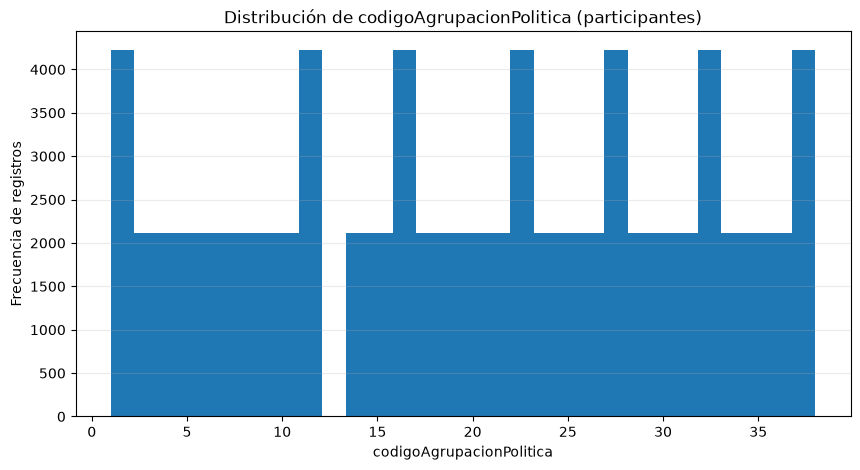

Interpretación: este histograma muestra cómo se distribuyen los valores de 'codigoAgrupacionPolitica'.


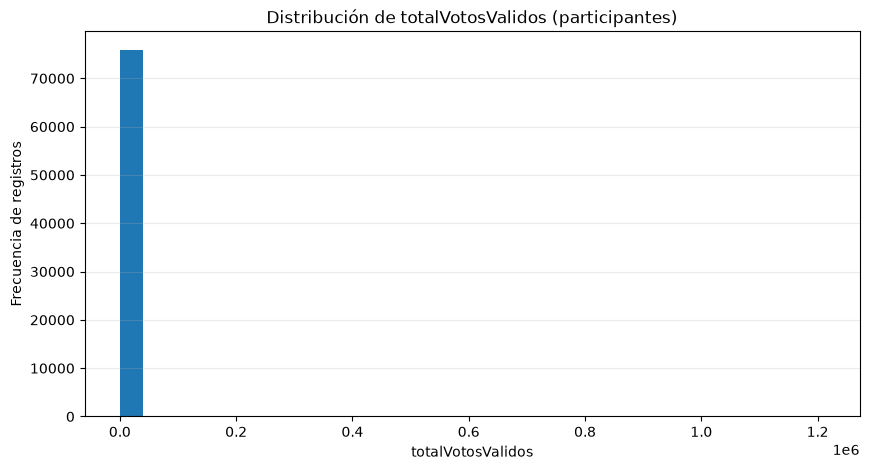

Interpretación: este histograma muestra cómo se distribuyen los valores de 'totalVotosValidos'.


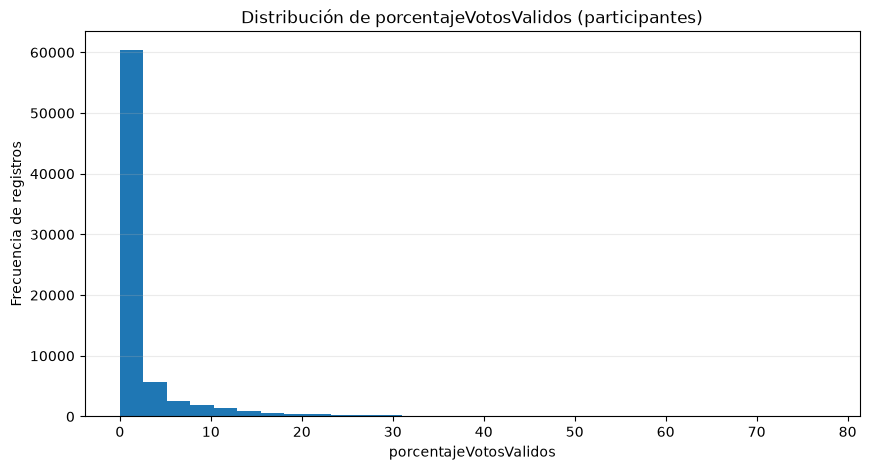

Interpretación: este histograma muestra cómo se distribuyen los valores de 'porcentajeVotosValidos'.


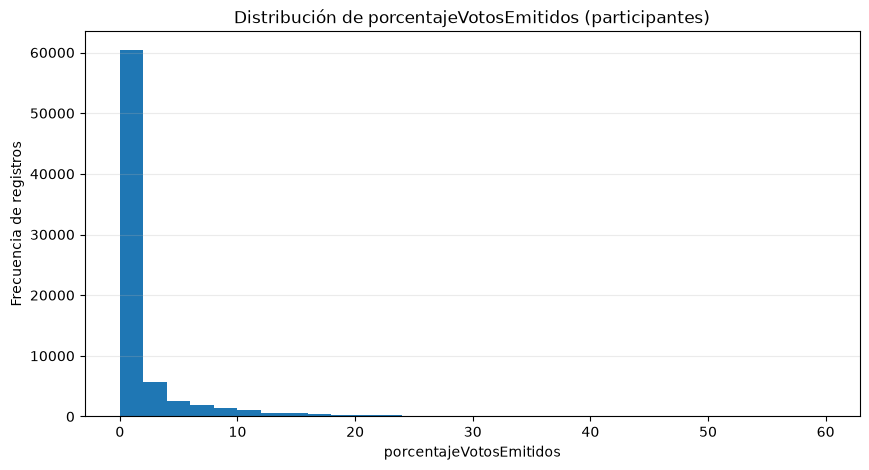

Interpretación: este histograma muestra cómo se distribuyen los valores de 'porcentajeVotosEmitidos'.


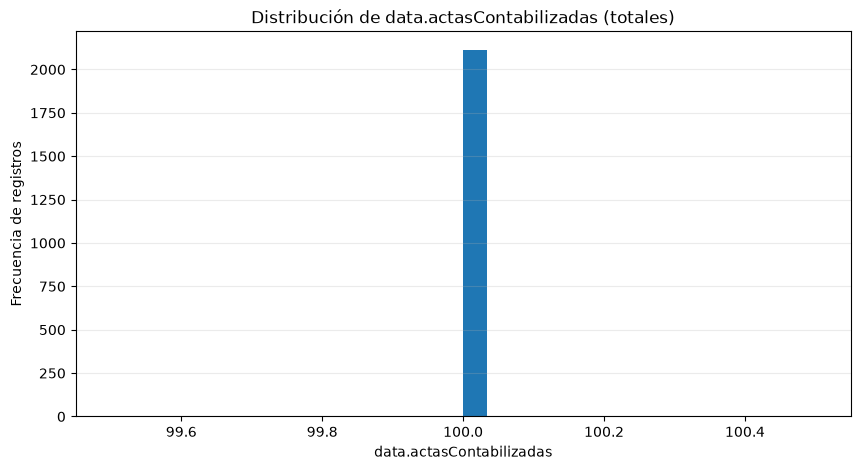

Interpretación: este histograma muestra cómo se distribuyen los valores de 'data.actasContabilizadas'.


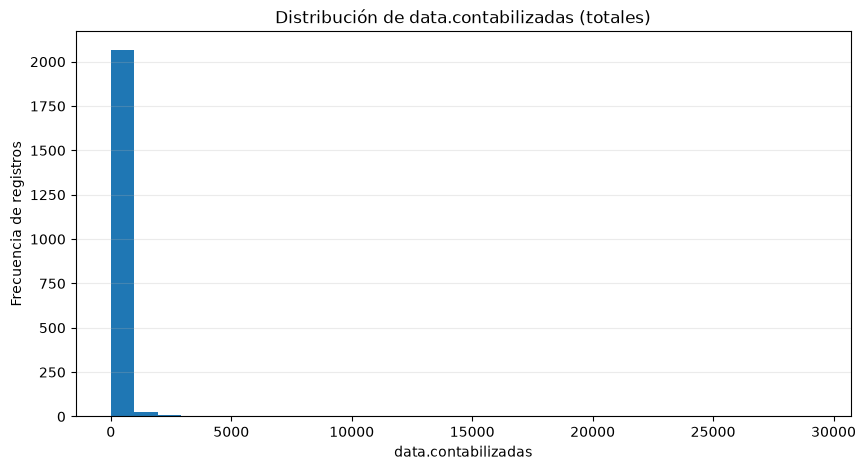

Interpretación: este histograma muestra cómo se distribuyen los valores de 'data.contabilizadas'.


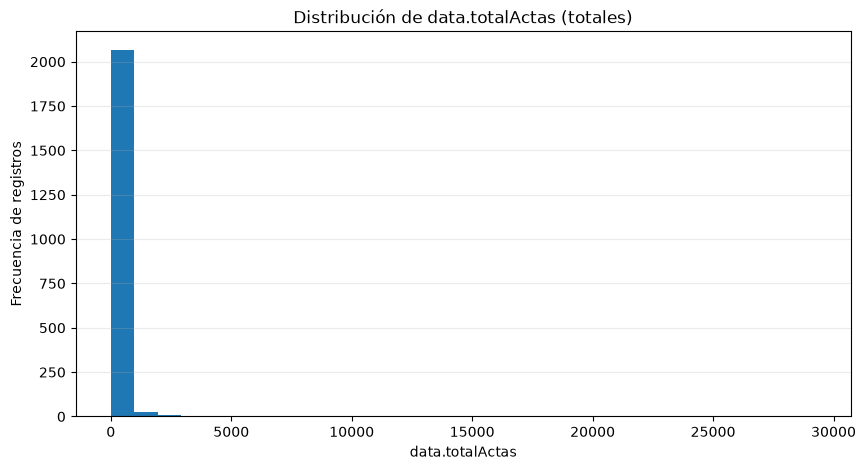

Interpretación: este histograma muestra cómo se distribuyen los valores de 'data.totalActas'.


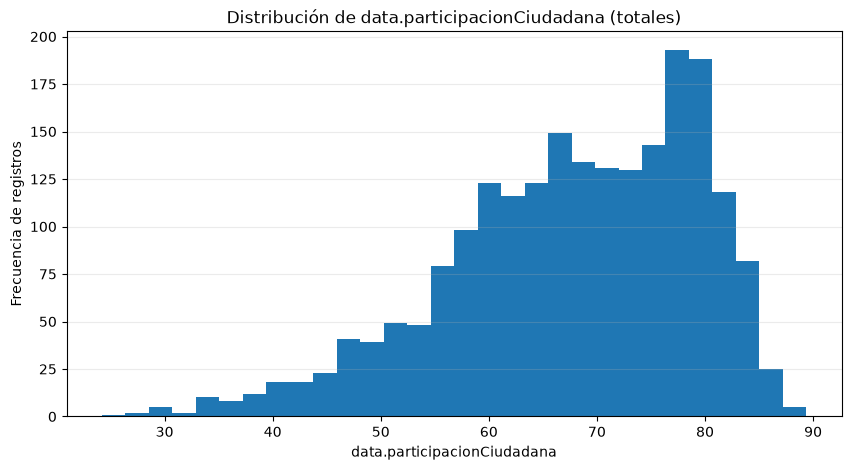

Interpretación: este histograma muestra cómo se distribuyen los valores de 'data.participacionCiudadana'.


In [21]:
def plot_numeric_histograms(df, name, max_columns=4):
    if df.empty:
        print(f"{name}: no hay datos para graficar.")
        return

    numeric_cols = list(df.select_dtypes(include="number").columns[:max_columns])
    if not numeric_cols:
        print(f"{name}: no se detectaron columnas numéricas.")
        return

    for column in numeric_cols:
        values = df[column].dropna()
        if values.empty:
            continue

        plt.figure()
        plt.hist(values, bins=30)
        plt.title(f"Distribución de {column} ({name})")
        plt.xlabel(column)
        plt.ylabel("Frecuencia de registros")
        plt.grid(axis="y", alpha=0.25)
        plt.show()

        print(
            f"Interpretación: este histograma muestra cómo se distribuyen los valores "
            f"de '{column}'."
        )

plot_numeric_histograms(df_participantes, "participantes")
plot_numeric_histograms(df_totales, "totales")

### 6.2 Frecuencia de categorías

Para las columnas categóricas se mostrarán las categorías más frecuentes. Esto ayuda a reconocer organizaciones políticas, estados, tipos de registro u otras categorías que existan realmente en los JSON.

In [22]:
def plot_top_categories(df, name, max_columns=3, top_n=15):
    if df.empty:
        return

    candidates = [
        col for col in df.columns
        if df[col].dtype == "object" and col != "source_file"
        and 1 < df[col].nunique(dropna=True) <= 100
    ][:max_columns]

    if not candidates:
        print(f"{name}: no se encontraron columnas categóricas adecuadas.")
        return

    for column in candidates:
        counts = df[column].fillna("NULO").astype(str).value_counts().head(top_n)
        plt.figure(figsize=(10, max(4, len(counts) * 0.3)))
        counts.sort_values().plot(kind="barh")
        plt.title(f"Categorías más frecuentes: {column} ({name})")
        plt.xlabel("Cantidad de registros")
        plt.ylabel(column)
        plt.grid(axis="x", alpha=0.25)
        plt.tight_layout()
        plt.show()

        print(
            f"Interpretación: el gráfico muestra las {len(counts)} categorías más frecuentes "
            f"en '{column}'. No representa cantidad de votos salvo que la variable graficada "
            "sea explícitamente una variable de votos."
        )

plot_top_categories(df_participantes, "participantes")
plot_top_categories(df_totales, "totales")

participantes: no se encontraron columnas categóricas adecuadas.
totales: no se encontraron columnas categóricas adecuadas.


### 6.3 Cobertura geográfica

Si se detecta un campo UBIGEO, se calculará la cantidad de códigos geográficos distintos. Este indicador permite conocer la cobertura observada en los archivos cargados.

**Precaución:** el número de UBIGEO distintos no debe interpretarse automáticamente como número de distritos, provincias o departamentos. Para asignar el nivel territorial es necesario comprobar la longitud y el catálogo geográfico utilizado por ONPE.

participantes: no se detectó una columna UBIGEO.
totales - columna data.idUbigeoDepartamento
Registros con UBIGEO: 2113
UBIGEO distintos: 1
Longitudes observadas:


,cantidad
data.idUbigeoDepartamento,
6,2113


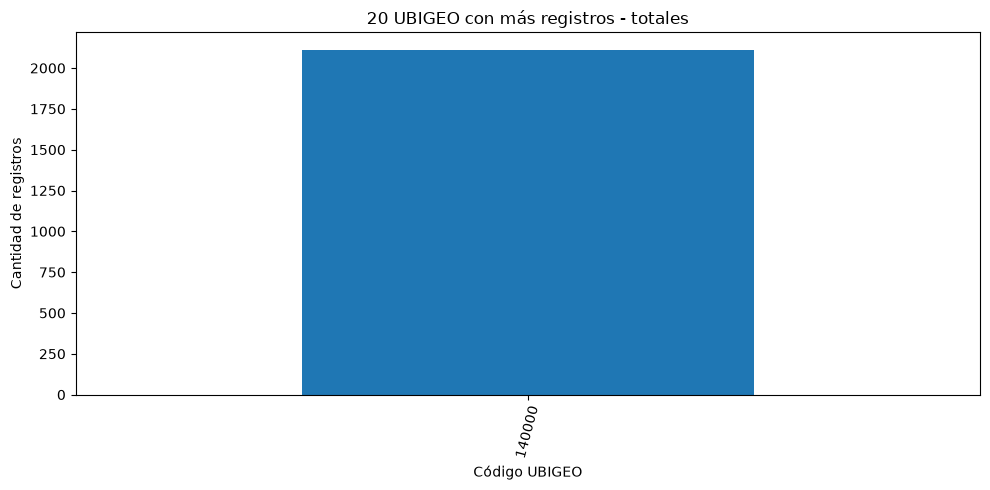

Interpretación: el gráfico muestra la frecuencia de registros por código UBIGEO. Una frecuencia alta puede deberse a que un distrito contiene resultados de varias organizaciones políticas; no implica por sí sola un error.
totales - columna data.idUbigeoProvincia
Registros con UBIGEO: 2113
UBIGEO distintos: 1
Longitudes observadas:


,cantidad
data.idUbigeoProvincia,
6,2113


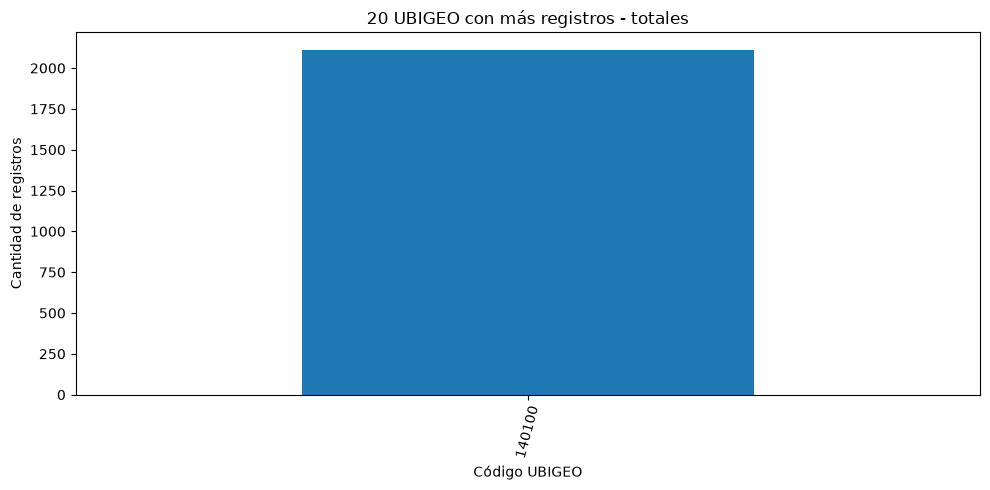

Interpretación: el gráfico muestra la frecuencia de registros por código UBIGEO. Una frecuencia alta puede deberse a que un distrito contiene resultados de varias organizaciones políticas; no implica por sí sola un error.
totales - columna data.idUbigeoDistrito
Registros con UBIGEO: 2113
UBIGEO distintos: 1
Longitudes observadas:


,cantidad
data.idUbigeoDistrito,
6,2113


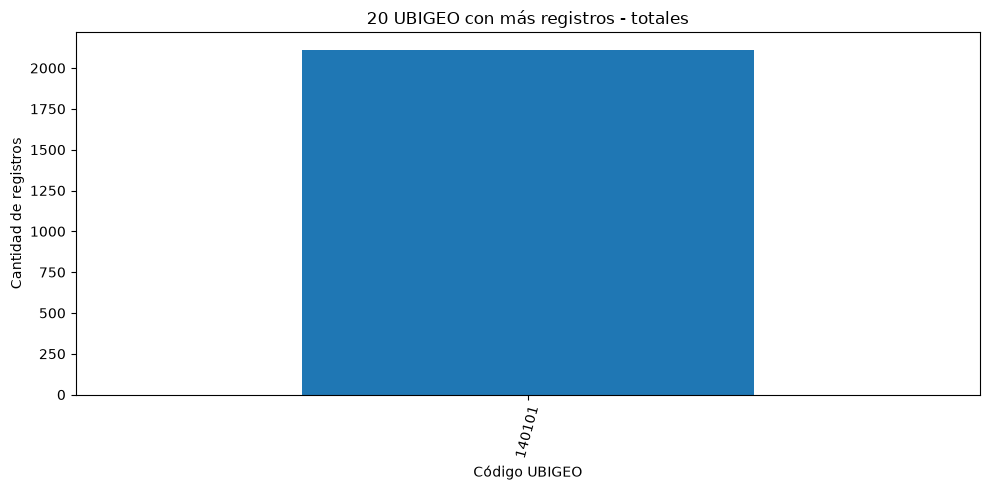

Interpretación: el gráfico muestra la frecuencia de registros por código UBIGEO. Una frecuencia alta puede deberse a que un distrito contiene resultados de varias organizaciones políticas; no implica por sí sola un error.
totales - columna data.idUbigeoDistritoElectoral
Registros con UBIGEO: 2113
UBIGEO distintos: 1
Longitudes observadas:


,cantidad
data.idUbigeoDistritoElectoral,
2,2113


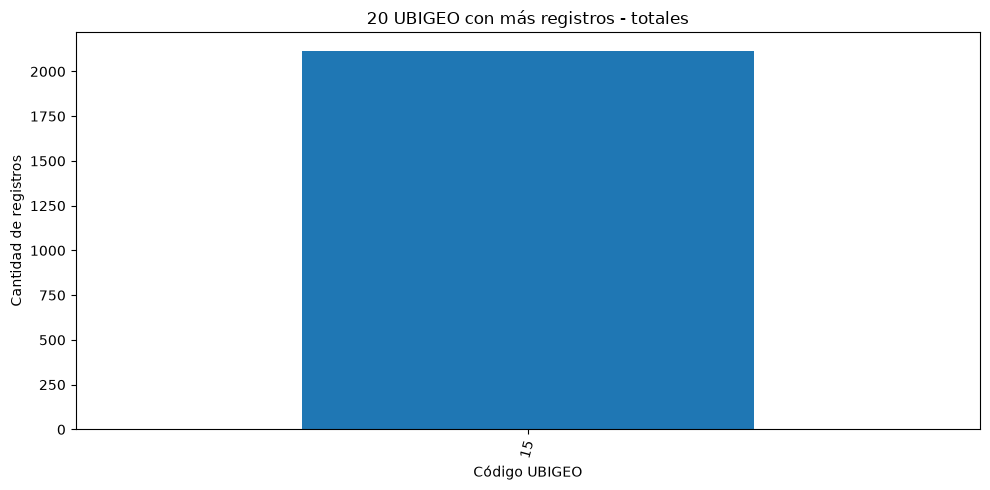

Interpretación: el gráfico muestra la frecuencia de registros por código UBIGEO. Una frecuencia alta puede deberse a que un distrito contiene resultados de varias organizaciones políticas; no implica por sí sola un error.


In [23]:
def geographic_coverage(df, name):
    ubigeo_cols = find_columns(df).get("ubigeo", [])
    if not ubigeo_cols:
        print(f"{name}: no se detectó una columna UBIGEO.")
        return

    for column in ubigeo_cols:
        values = df[column].dropna().astype(str).str.strip()
        print(f"{name} - columna {column}")
        print("Registros con UBIGEO:", len(values))
        print("UBIGEO distintos:", values.nunique())
        print("Longitudes observadas:")
        display(values.str.len().value_counts().sort_index().to_frame("cantidad"))

        counts = values.value_counts().head(20)
        plt.figure(figsize=(10, 5))
        counts.sort_values().plot(kind="bar")
        plt.title(f"20 UBIGEO con más registros - {name}")
        plt.xlabel("Código UBIGEO")
        plt.ylabel("Cantidad de registros")
        plt.xticks(rotation=75)
        plt.tight_layout()
        plt.show()

        print(
            "Interpretación: el gráfico muestra la frecuencia de registros por código UBIGEO. "
            "Una frecuencia alta puede deberse a que un distrito contiene resultados de varias "
            "organizaciones políticas; no implica por sí sola un error."
        )

geographic_coverage(df_participantes, "participantes")
geographic_coverage(df_totales, "totales")

### 6.4 Cobertura de los catálogos geográficos

Se calcula la cobertura de códigos UBIGEO de cada catálogo utilizando la función de la sección 6.3. En condiciones normales, los catálogos representan niveles territoriales diferentes; por ello, sus cantidades de códigos no deben sumarse entre sí.

catálogo de departamentos - columna ubigeo
Registros con UBIGEO: 25
UBIGEO distintos: 25
Longitudes observadas:


,cantidad
ubigeo,
6,25


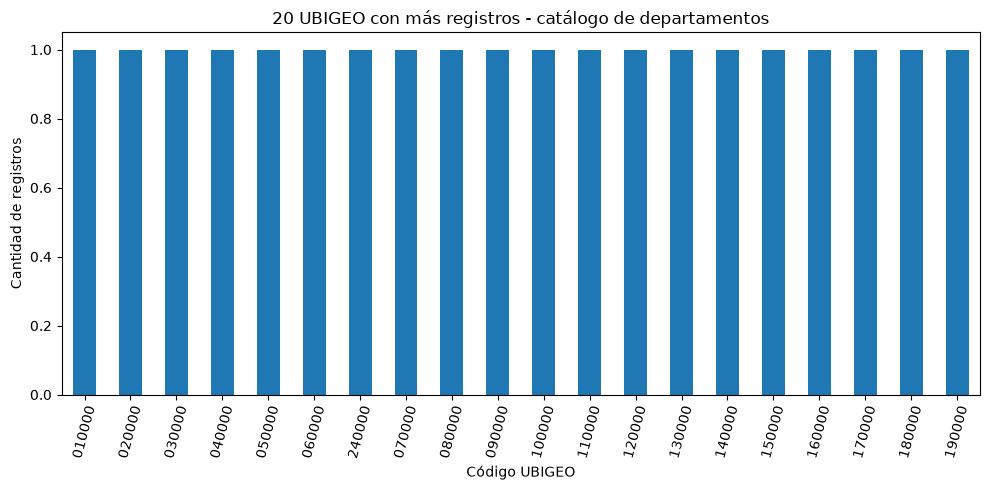

Interpretación: el gráfico muestra la frecuencia de registros por código UBIGEO. Una frecuencia alta puede deberse a que un distrito contiene resultados de varias organizaciones políticas; no implica por sí sola un error.
catálogo de provincias - columna ubigeo
Registros con UBIGEO: 196
UBIGEO distintos: 196
Longitudes observadas:


,cantidad
ubigeo,
6,196


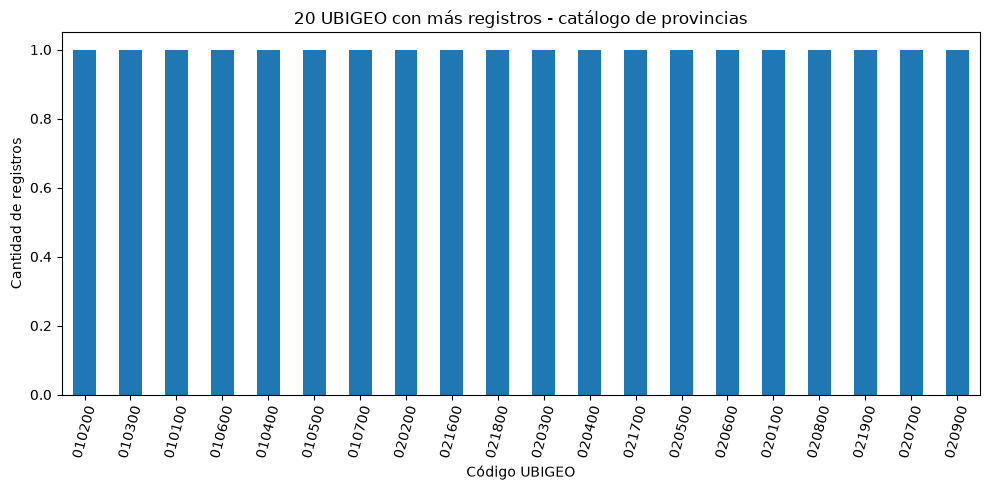

Interpretación: el gráfico muestra la frecuencia de registros por código UBIGEO. Una frecuencia alta puede deberse a que un distrito contiene resultados de varias organizaciones políticas; no implica por sí sola un error.
catálogo de distritos - columna ubigeo
Registros con UBIGEO: 1892
UBIGEO distintos: 1892
Longitudes observadas:


,cantidad
ubigeo,
6,1892


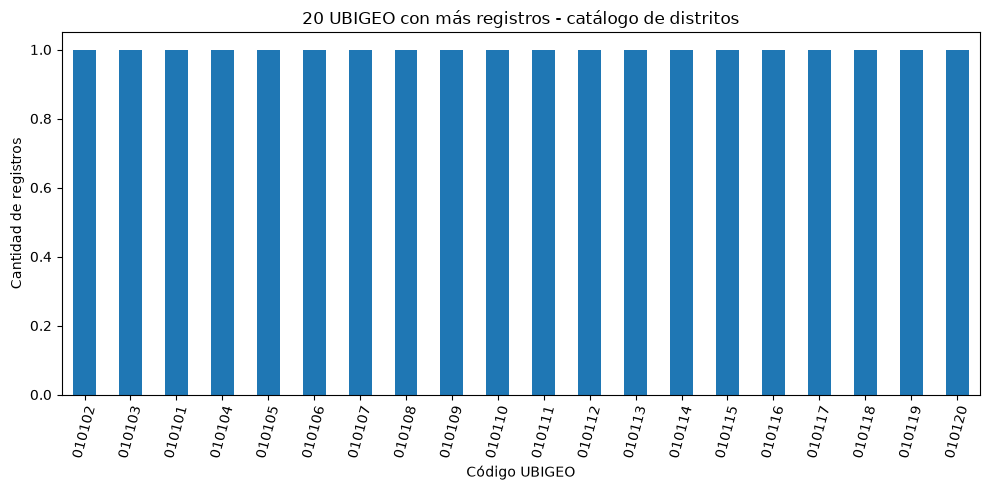

Interpretación: el gráfico muestra la frecuencia de registros por código UBIGEO. Una frecuencia alta puede deberse a que un distrito contiene resultados de varias organizaciones políticas; no implica por sí sola un error.


In [24]:
geographic_coverage(df_departamentos, "catálogo de departamentos")
geographic_coverage(df_provincias, "catálogo de provincias")
geographic_coverage(df_distritos, "catálogo de distritos")

### 6.5 Resumen de cobertura de los catálogos

Se presenta una tabla compacta con el número de registros y códigos UBIGEO distintos detectados en cada catálogo. El cálculo se realiza únicamente cuando se identifica una columna candidata a UBIGEO.

In [25]:
catalog_summary = []

for catalog_name, catalog_df in [
    ("departamentos", df_departamentos),
    ("provincias", df_provincias),
    ("distritos", df_distritos)
]:
    ubigeo_candidates = find_columns(catalog_df).get("ubigeo", [])

    if ubigeo_candidates:
        # Se utiliza la primera columna detectada; revisar la inspección de campos
        # si el catálogo contiene más de una columna candidata.
        ubigeo_col = ubigeo_candidates[0]
        ubigeo_values = catalog_df[ubigeo_col].dropna().astype(str).str.strip()

        catalog_summary.append({
            "catalogo": catalog_name,
            "filas": len(catalog_df),
            "columna_ubigeo": ubigeo_col,
            "ubigeo_distintos": ubigeo_values.nunique(),
            "ubigeo_nulos": int(catalog_df[ubigeo_col].isna().sum())
        })
    else:
        catalog_summary.append({
            "catalogo": catalog_name,
            "filas": len(catalog_df),
            "columna_ubigeo": None,
            "ubigeo_distintos": None,
            "ubigeo_nulos": None
        })

df_catalog_summary = pd.DataFrame(catalog_summary)
display(df_catalog_summary)

,catalogo,filas,columna_ubigeo,ubigeo_distintos,ubigeo_nulos
0,departamentos,25,ubigeo,25,0
1,provincias,196,ubigeo,196,0
2,distritos,1892,ubigeo,1892,0


## 7. Relaciones y consistencia de los resultados

### 7.1 Archivos por tipo y correspondencia

Si los JSON están organizados en carpetas por ámbito geográfico, se puede revisar cuántos archivos existen por nombre y si hay diferencias entre la cantidad de archivos `participantes.json` y `totales.json`.

In [26]:
file_counts = df_inventory["archivo"].value_counts() if not df_inventory.empty else pd.Series(dtype=int)
display(file_counts.to_frame("cantidad_archivos"))

participant_paths = {
    str(p.parent.relative_to(DATA_DIR))
    for p in json_files if p.name.lower() == "participantes.json"
}
total_paths = {
    str(p.parent.relative_to(DATA_DIR))
    for p in json_files if p.name.lower() == "totales.json"
}

print("Carpetas con participantes.json:", len(participant_paths))
print("Carpetas con totales.json:", len(total_paths))
print("Carpetas con ambos archivos:", len(participant_paths & total_paths))
print("Solo participantes:", len(participant_paths - total_paths))
print("Solo totales:", len(total_paths - participant_paths))

,cantidad_archivos
archivo,
participantes.json,2113
totales.json,2113
distritos.json,196
provincias.json,25
departamentos.json,1
participantes_nacional.json,1
totales_nacional.json,1


Carpetas con participantes.json: 2113
Carpetas con totales.json: 2113
Carpetas con ambos archivos: 2113
Solo participantes: 0
Solo totales: 0


### 7.2 Comprobación exploratoria de sumas de votos

Si el archivo `participantes.json` contiene una cantidad de votos por organización política y `totales.json` contiene el total de votos válidos, se puede contrastar la suma de votos por organización con el total correspondiente al mismo ámbito geográfico.

In [27]:

# ============================================================
# 7.2 COMPROBACIÓN DE LA SUMA DE VOTOS POR DISTRITO
# ============================================================
# participantes.json:
#   - totalVotosValidos: votos válidos por organización política.
#
# totales.json:
#   - data.idUbigeoDistrito: código UBIGEO del distrito.
#   - data.totalVotosValidos: total de votos válidos del distrito.
#
# Los archivos participantes.json y totales.json se encuentran
# en la misma carpeta del distrito. Utilizaremos esa ruta para
# relacionar ambos conjuntos de datos.

from pathlib import Path

# 1. Definir los nombres reales de los campos.
PART_VOTES_COL = "totalVotosValidos"
TOTAL_UBIGEO_COL = "data.idUbigeoDistrito"
TOTAL_VALID_VOTES_COL = "data.totalVotosValidos"

# 2. Crear una clave común a partir de la carpeta de cada archivo.
# source_file contiene la ruta relativa del JSON de origen.
df_participantes["source_dir"] = df_participantes[
    "source_file"
].apply(lambda x: str(Path(x).parent))

df_totales["source_dir"] = df_totales[
    "source_file"
].apply(lambda x: str(Path(x).parent))

# 3. Verificar que existan las columnas requeridas.
required_part = ["source_dir", PART_VOTES_COL]
required_total = [
    "source_dir",
    TOTAL_UBIGEO_COL,
    TOTAL_VALID_VOTES_COL
]

missing_part = [
    col for col in required_part
    if col not in df_participantes.columns
]

missing_total = [
    col for col in required_total
    if col not in df_totales.columns
]

if missing_part or missing_total:
    print("No se puede realizar la conciliación.")
    print("Columnas faltantes en participantes:", missing_part)
    print("Columnas faltantes en totales:", missing_total)

else:
    # 4. Preparar los datos de participantes.
    participantes = df_participantes[
        ["source_dir", PART_VOTES_COL]
    ].copy()

    participantes[PART_VOTES_COL] = pd.to_numeric(
        participantes[PART_VOTES_COL],
        errors="coerce"
    )

    # 5. Sumar los votos de todas las organizaciones políticas
    # correspondientes a cada carpeta/distrito.
    votos_por_distrito = (
        participantes
        .groupby("source_dir")[PART_VOTES_COL]
        .sum(min_count=1)
        .reset_index()
        .rename(columns={
            PART_VOTES_COL: "suma_votos_participantes"
        })
    )

    # 6. Preparar los totales por distrito.
    totales = df_totales[
        ["source_dir", TOTAL_UBIGEO_COL, TOTAL_VALID_VOTES_COL]
    ].copy()

    totales[TOTAL_VALID_VOTES_COL] = pd.to_numeric(
        totales[TOTAL_VALID_VOTES_COL],
        errors="coerce"
    )

    # 7. Relacionar participantes y totales mediante la carpeta.
    reconciliation = votos_por_distrito.merge(
        totales,
        on="source_dir",
        how="outer",
        validate="one_to_one"
    )

    # 8. Calcular la diferencia entre ambas fuentes.
    reconciliation["diferencia"] = (
        reconciliation["suma_votos_participantes"]
        - reconciliation[TOTAL_VALID_VOTES_COL]
    )

    # 9. Comprobar si los valores coinciden.
    reconciliation["coincide"] = np.isclose(
        reconciliation["suma_votos_participantes"],
        reconciliation[TOTAL_VALID_VOTES_COL],
        equal_nan=False
    )

    # 10. Mostrar resultados.
    print("DISTRITOS CONCILIADOS:", len(reconciliation))
    print(
        "Coincidencias:",
        int(reconciliation["coincide"].sum())
    )
    print(
        "Diferencias:",
        int((~reconciliation["coincide"]).sum())
    )

    print("\nDetalle de la conciliación:")
    display(
        reconciliation[
            [
                TOTAL_UBIGEO_COL,
                "suma_votos_participantes",
                TOTAL_VALID_VOTES_COL,
                "diferencia",
                "coincide"
            ]
        ].head(20)
    )

    # 11. Mostrar únicamente los distritos con diferencias.
    diferencias = reconciliation[
        reconciliation["coincide"] == False
    ]

    print("\nDistritos con diferencias:")
    display(diferencias.head(20))

    # 12. Guardar el resultado para documentar el EDA.
    reconciliation.to_csv(
        OUTPUT_DIR / "conciliacion_votos_por_distrito.csv",
        index=False,
        encoding="utf-8-sig"
    )


DISTRITOS CONCILIADOS: 2113
Coincidencias: 2113
Diferencias: 0

Detalle de la conciliación:


,data.idUbigeoDistrito,suma_votos_participantes,data.totalVotosValidos,diferencia,coincide
0,140101,163482,163482,0,True
1,140101,25579,25579,0,True
2,140101,13472,13472,0,True
3,140101,121,121,0,True
4,140101,611,611,0,True
5,140101,365,365,0,True
6,140101,380,380,0,True
7,140101,469,469,0,True
8,140101,321,321,0,True
9,140101,522,522,0,True



Distritos con diferencias:


,source_dir,suma_votos_participantes,data.idUbigeoDistrito,data.totalVotosValidos,diferencia,coincide


## 8. Registro de resultados y reproducibilidad

Se guardarán automáticamente el inventario, perfiles de columnas, resúmenes de nulos y duplicados, y un log de ejecución. Estos archivos permiten revisar qué datos se analizaron y qué resultados produjo el notebook.

La reproducibilidad requiere conservar:
- Fecha y hora de ejecución.
- Semilla utilizada.
- Ruta y huella SHA-256 del conjunto de datos.
- Versiones de Python y bibliotecas.
- Notebook y scripts utilizados.

In [28]:
import platform
import sys

run_timestamp = datetime.now().isoformat(timespec="seconds")

# Guardar tablas de diagnóstico cuando existan.
tables_to_save = {
    "inventory.csv": df_inventory,
    "nulls_participantes.csv": nulls_participantes,
    "nulls_totales.csv": nulls_totales,
    "profile_participantes.csv": profile_participantes,
    "profile_totales.csv": profile_totales,
    "duplicate_summary.csv": duplicate_results
}

for filename, table in tables_to_save.items():
    if isinstance(table, pd.DataFrame) and not table.empty:
        table.to_csv(OUTPUT_DIR / filename, index=True, encoding="utf-8-sig")

run_info = {
    "fecha_hora_ejecucion": run_timestamp,
    "python": sys.version,
    "plataforma": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "random_seed": RANDOM_SEED,
    "data_dir": str(DATA_DIR),
    "cantidad_archivos_json": len(json_files),
    "sha256_conjunto_archivos": DATASET_SHA256
}

with (OUTPUT_DIR / "eda_run_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(run_info, file, ensure_ascii=False, indent=2)

log_lines = [
    f"Fecha de ejecución: {run_timestamp}",
    f"Archivos JSON encontrados: {len(json_files)}",
    f"Registros participantes: {len(df_participantes)}",
    f"Registros totales: {len(df_totales)}",
    f"Errores de carga participantes: {len(errors_participantes)}",
    f"Errores de carga totales: {len(errors_totales)}",
    f"SHA-256: {DATASET_SHA256}",
    f"Semilla: {RANDOM_SEED}"
]

(OUTPUT_DIR / "eda_metrics.txt").write_text("\n".join(log_lines), encoding="utf-8")

print("Resultados guardados en:", OUTPUT_DIR)
print("\n".join(log_lines))

Resultados guardados en: c:\Users\Kencho\Desktop\MaestriaIA\Trabajo Investigacion II\Repositorio\ProyectoTesis\results\eda
Fecha de ejecución: 2026-11-13T00:45:35
Archivos JSON encontrados: 4450
Registros participantes: 76068
Registros totales: 2113
Errores de carga participantes: 0
Errores de carga totales: 0
SHA-256: 57f1c04bbae4c4e066bdbe9879521a56bab2442f5d5569ac8aeec87ed14d4058
Semilla: 31
